# 01 — EDA e pré-processamento

**Projeto Respira** — estimativa de nível de ansiedade a partir de hábitos e sinais vitais
Entrega 2 · Machine Learning · Projeto Final · *Dados prontos*

Ordem do notebook:

1. setup e carga;
2. `limpar(df)` — só operações linha a linha, **antes** do split;
3. split 80/20 com `random_state=42` (o mesmo da E1) — o teste fica trancado;
4. EDA com as cinco perguntas, só em `X_tr` e `y_tr`, cada gráfico com **Observação** e **Decisão**;
5. pré-processador (`ColumnTransformer`);
6. teste de sanidade (sem NaN, cross-val, comparação com baseline);
7. tabela de decisões.

> Regra: tudo que for aprendido dos dados acontece só com o treino. `X_te` e `y_te` não aparecem em nenhuma decisão.

---
## 1. Setup e carga

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)

SEED = 42
ALVO = "Anxiety Level (1-10)"

NOME = "enhanced_anxiety_dataset.csv"
CANDIDATOS = [f"../data/raw/{NOME}", f"data/raw/{NOME}", NOME, f"/content/{NOME}"]
CAMINHO = next((c for c in CANDIDATOS if os.path.exists(c)), None)
if CAMINHO is None:
    try:
        from google.colab import files
        print(f"Selecione o arquivo {NOME}:")
        CAMINHO = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError(f"{NOME} nao encontrado. Coloque em data/raw/.")

print("Lendo:", CAMINHO)
df_bruto = pd.read_csv(CAMINHO)
print("Shape bruto:", df_bruto.shape)

Lendo: ../data/raw/enhanced_anxiety_dataset.csv
Shape bruto: (11000, 19)


---
## 2. `limpar(df)` — antes do split

Só entra aqui o que **não precisa olhar as outras linhas** (pergunta-teste da aula). Isso inclui:

- remover duplicatas exatas e colunas de ID (o dataset não tem ID);
- padronizar texto: `"yes "`, `"YES"`, `"Y"`, `"sim"` → `"Yes"`;
- ausentes disfarçados (`"?"`, `"NA"`, `""`) → `NaN`;
- limites de **domínio** (idade entre 0 e 120, sono entre 0 e 24 h, escalas 1–10…) → fora do limite vira `NaN` e o imputer do pipeline resolve. Isso também cobre sentinelas numéricas como `-1` e `999`, sem tocar no `0`, que é valor válido em álcool, cafeína e terapia.

Esta mesma função vai rodar na API (E4), antes do pipeline. Ela **não mexe no alvo**.

In [2]:
COLS_BINARIAS = ["Smoking", "Family History of Anxiety", "Dizziness",
                 "Medication", "Recent Major Life Event"]
COLS_NOMINAIS = ["Gender", "Occupation"]

# limites de dominio (min, max) -- nao aprendem nada dos dados
LIMITES = {
    "Age": (0, 120),
    "Sleep Hours": (0, 24),
    "Physical Activity (hrs/week)": (0, 168),
    "Caffeine Intake (mg/day)": (0, 2000),
    "Alcohol Consumption (drinks/week)": (0, 200),
    "Stress Level (1-10)": (1, 10),
    "Heart Rate (bpm)": (30, 220),
    "Breathing Rate (breaths/min)": (4, 60),
    "Sweating Level (1-5)": (1, 5),
    "Therapy Sessions (per month)": (0, 31),
    "Diet Quality (1-10)": (1, 10),
}
COLS_NUMERICAS = list(LIMITES)

AUSENTES_TEXTO = {"", "?", "na", "n/a", "nan", "none", "null", "-"}
SIM = {"yes", "y", "sim", "s", "true", "1"}
NAO = {"no", "n", "nao", "não", "false", "0"}

def _bin(v):
    if pd.isna(v): return np.nan
    t = str(v).strip().lower()
    if t in AUSENTES_TEXTO: return np.nan
    if t in SIM: return "Yes"
    if t in NAO: return "No"
    return np.nan  # valor desconhecido numa binaria: trata como ausente

def _txt(v):
    if pd.isna(v): return np.nan
    t = str(v).strip()
    return np.nan if t.lower() in AUSENTES_TEXTO else t.title()

def limpar(df, verbose=False):
    """Limpeza linha a linha. Nao aprende nada dos dados; roda igual no treino e na API."""
    d = df.copy()
    d.columns = [c.strip() for c in d.columns]
    d = d.drop_duplicates()
    for c in COLS_BINARIAS:
        if c in d: d[c] = d[c].map(_bin)
    for c in COLS_NOMINAIS:
        if c in d: d[c] = d[c].map(_txt)
    for c, (lo, hi) in LIMITES.items():
        if c in d:
            d[c] = pd.to_numeric(d[c], errors="coerce")
            fora = (d[c] < lo) | (d[c] > hi)
            if verbose and fora.sum():
                print(f"  {c}: {int(fora.sum())} valores fora de [{lo}, {hi}] -> NaN")
            d.loc[fora, c] = np.nan
    return d

df = limpar(df_bruto, verbose=True)
print("Linhas removidas pela limpeza:", len(df_bruto) - len(df))
print("Nulos criados pela limpeza (X):", int(df.drop(columns=[ALVO]).isna().sum().sum()))
assert df[ALVO].notna().all(), "alvo com NaN: decidir antes de seguir"
df.head()

Linhas removidas pela limpeza: 0
Nulos criados pela limpeza (X): 0


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10)
0,29.0,Female,Artist,6.0,2.7,181.0,10.0,Yes,No,10.0,114.0,14.0,4.0,No,Yes,3.0,Yes,7.0,5.0
1,46.0,Other,Nurse,6.2,5.7,200.0,8.0,Yes,Yes,1.0,62.0,23.0,2.0,Yes,No,2.0,No,8.0,3.0
2,64.0,Male,Other,5.0,3.7,117.0,4.0,No,Yes,1.0,91.0,28.0,3.0,No,No,1.0,Yes,1.0,1.0
3,20.0,Female,Scientist,5.8,2.8,360.0,6.0,Yes,No,4.0,86.0,17.0,3.0,No,No,0.0,No,1.0,2.0
4,49.0,Female,Other,8.2,2.3,247.0,4.0,Yes,No,1.0,98.0,19.0,4.0,Yes,Yes,1.0,No,3.0,1.0


---
## 3. Split (o mesmo da E1)

`test_size=0.2`, `random_state=42`. O alvo é contínuo, então não há `stratify` (isso vale para classificação). A partir daqui, a EDA só olha `X_tr` e `y_tr`.

In [3]:
X = df.drop(columns=[ALVO])
y = df[ALVO]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Treino: {len(X_tr):,}   Teste (trancado): {len(X_te):,}")
dados = X_tr.assign(**{ALVO: y_tr})   # so treino, para a EDA

Treino: 8,800   Teste (trancado): 2,200


---
## 4. EDA — cinco perguntas, cada uma termina numa decisão

### Pergunta 1 — Como o alvo se distribui?

count    8800.00
mean        3.92
std         2.11
min         1.00
25%         2.00
50%         4.00
75%         5.00
max        10.00

Anxiety Level (1-10)
1.0      9.5
2.0     15.8
3.0     21.9
4.0     22.2
5.0     14.8
6.0      5.7
7.0      1.1
8.0      3.2
9.0      2.9
10.0     2.9

Notas 8 a 10: 9.0% do treino


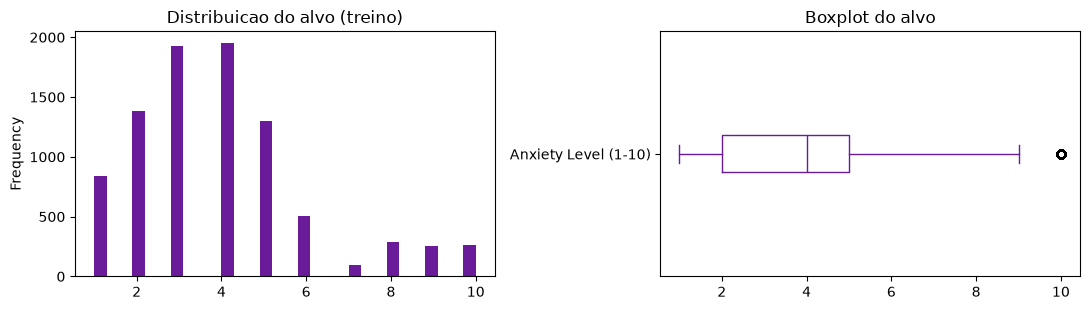

In [4]:
print(y_tr.describe().round(2).to_string())
print()
cont = y_tr.round().value_counts().sort_index()
print((cont / len(y_tr) * 100).round(1).rename("% do treino").to_string())
alto = (y_tr >= 8).mean() * 100
print(f"\nNotas 8 a 10: {alto:.1f}% do treino")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
y_tr.plot(kind="hist", bins=30, ax=ax[0], color="#6A1B9A")
ax[0].set_title("Distribuicao do alvo (treino)")
y_tr.plot(kind="box", vert=False, ax=ax[1], color="#6A1B9A")
ax[1].set_title("Boxplot do alvo")
plt.tight_layout(); plt.show()

**Observação:** o alvo vai de 1 a 10, com média 3,92 e desvio 2,11. A maior parte das notas está entre 1 e 5. As notas 8 a 10 são raras (**9,0% do treino**) e a cauda não decai de forma suave: a nota 7 tem só 1,1%, enquanto 8, 9 e 10 têm cerca de 3% cada, um degrau compatível com dado sintético truncado em 10.

**Decisão:** não há classes, então não há `stratify` nem `class_weight`. Mantém MAE como métrica principal. Registrado para a E3: o modelo tende a errar mais nas notas altas (8 a 10); avaliar `sample_weight` para elas.

### Pergunta 2 — Onde faltam dados?

In [5]:
falt = X_tr.isna().mean().sort_values(ascending=False) * 100
print(falt.round(2).to_string())
print(f"\nTotal de nulos em X_tr: {int(X_tr.isna().sum().sum())}")

# ausentes disfarcados: sentinelas numericas que passariam pela limpeza?
for c in COLS_NUMERICAS:
    lo, hi = LIMITES[c]
    print(f"{c:36s} min={X_tr[c].min():>8.1f}  max={X_tr[c].max():>8.1f}   dominio=[{lo}, {hi}]")

Age                                  0.0
Gender                               0.0
Occupation                           0.0
Sleep Hours                          0.0
Physical Activity (hrs/week)         0.0
Caffeine Intake (mg/day)             0.0
Alcohol Consumption (drinks/week)    0.0
Smoking                              0.0
Family History of Anxiety            0.0
Stress Level (1-10)                  0.0
Heart Rate (bpm)                     0.0
Breathing Rate (breaths/min)         0.0
Sweating Level (1-5)                 0.0
Dizziness                            0.0
Medication                           0.0
Therapy Sessions (per month)         0.0
Recent Major Life Event              0.0
Diet Quality (1-10)                  0.0

Total de nulos em X_tr: 0
Age                                  min=    18.0  max=    64.0   dominio=[0, 120]
Sleep Hours                          min=     2.3  max=    11.3   dominio=[0, 24]
Physical Activity (hrs/week)         min=     0.0  max=    10.1   domi

**Observação:** nenhuma coluna tem valores faltantes e nenhum valor ficou fora dos limites de domínio (a limpeza reportou 0 conversões). Consistente com dado sintético (E1).

**Decisão:** nenhuma ação sobre os dados de treino. **Mas** o pipeline mantém `SimpleImputer` em todos os caminhos: o usuário da API vai deixar campo vazio, e o pipeline precisa saber o que fazer. Como o percentual de faltantes é 0% (< 5%), sem `add_indicator`. Sem `dropna()`.

### Pergunta 3 — Como cada variável se distribui?

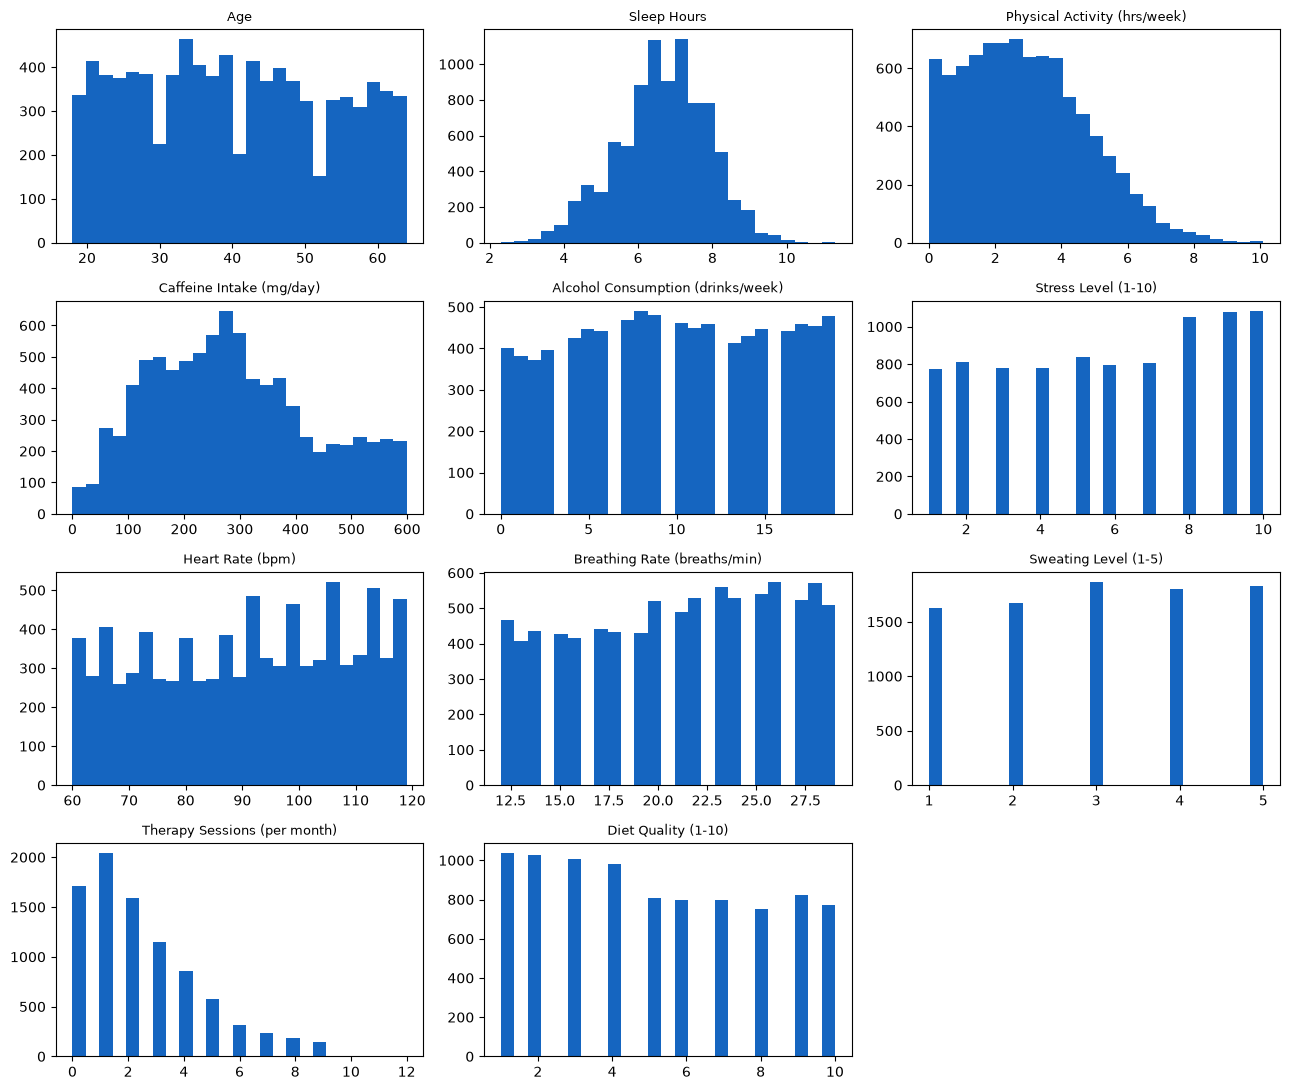

Assimetria (skew) -- |skew| > 1 sugere testar log:
Therapy Sessions (per month)         1.05
Physical Activity (hrs/week)         0.50
Caffeine Intake (mg/day)             0.32
Sleep Hours                         -0.24
Diet Quality (1-10)                  0.16
Stress Level (1-10)                 -0.15
Breathing Rate (breaths/min)        -0.15
Heart Rate (bpm)                    -0.13
Age                                  0.10
Sweating Level (1-5)                -0.06
Alcohol Consumption (drinks/week)   -0.03


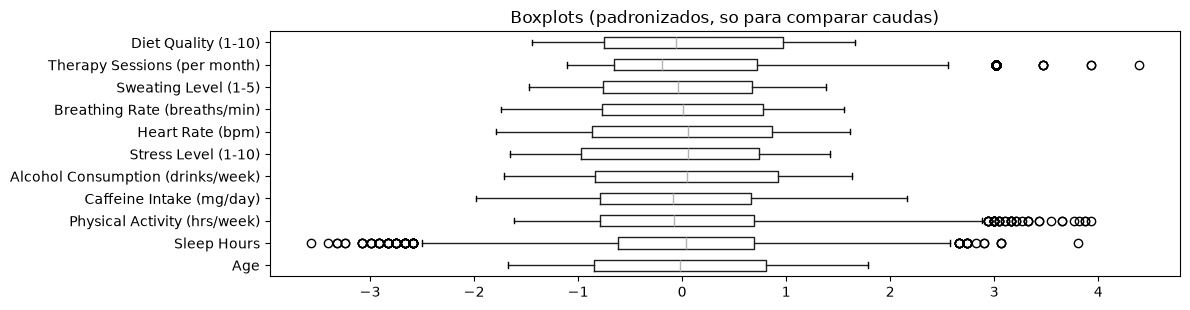

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(13, 11))
for ax, c in zip(axes.ravel(), COLS_NUMERICAS):
    X_tr[c].plot(kind="hist", bins=25, ax=ax, color="#1565C0")
    ax.set_title(c, fontsize=9); ax.set_ylabel("")
for ax in axes.ravel()[len(COLS_NUMERICAS):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

print("Assimetria (skew) -- |skew| > 1 sugere testar log:")
sk = X_tr[COLS_NUMERICAS].skew().sort_values(key=abs, ascending=False)
print(sk.round(2).to_string())

fig, ax = plt.subplots(figsize=(12, 3.2))
Z = (X_tr[COLS_NUMERICAS] - X_tr[COLS_NUMERICAS].mean()) / X_tr[COLS_NUMERICAS].std()
Z.boxplot(ax=ax, vert=False, grid=False)
ax.set_title("Boxplots (padronizados, so para comparar caudas)")
plt.tight_layout(); plt.show()

**Observação:** as 11 numéricas têm escalas muito diferentes (cafeína em centenas de mg, estresse de 1 a 10, idade em dezenas), mas as distribuições são quase simétricas. O maior |skew| é `Therapy Sessions` (1,05), seguida de `Physical Activity` (0,50); as outras nove ficam abaixo de 0,35.

**Decisão:** `StandardScaler` em todas as numéricas (escalas diferentes). Outliers: mantidos, são valores reais dentro do domínio. Só `Therapy Sessions` passa de |skew| > 1, e por pouco (1,05; é uma contagem com zeros): sem transformação agora, testar `log1p` na E3.

In [7]:
for c in COLS_BINARIAS + COLS_NOMINAIS:
    print(f"{c}: " + " | ".join(f"{k}: {v}" for k, v in X_tr[c].value_counts().items()))

Smoking: Yes: 4656 | No: 4144
Family History of Anxiety: Yes: 4664 | No: 4136
Dizziness: Yes: 4551 | No: 4249
Medication: Yes: 4545 | No: 4255
Recent Major Life Event: Yes: 4502 | No: 4298
Gender: Female: 2964 | Male: 2934 | Other: 2902
Occupation: Nurse: 721 | Student: 718 | Musician: 712 | Artist: 697 | Chef: 684 | Freelancer: 681 | Scientist: 672 | Other: 668 | Doctor: 655 | Engineer: 655 | Lawyer: 649 | Teacher: 644 | Athlete: 644


**Observação (categóricas):** `Gender` tem 3 categorias bem equilibradas (2964 / 2934 / 2902) e `Occupation` tem 13, cada uma com 644 a 721 linhas. As 5 binárias ficam em torno de 50/50 (ex.: `Smoking`, 4656 Yes e 4144 No). Nenhuma categoria rara ou desbalanceada.

**Decisão:** `Gender` e `Occupation` → nominais, `OneHotEncoder(handle_unknown="ignore")`. As 5 binárias → `OneHotEncoder(drop="if_binary")`. Nenhuma ordinal verdadeira (`Sweating`, `Stress` e `Diet` são escalas numéricas e entram como numéricas). Nenhuma coluna de ID ou texto livre.

### Pergunta 4 — O que se relaciona com o alvo?

Stress Level (1-10)                  0.670
Therapy Sessions (per month)         0.515
Sleep Hours                         -0.486
Caffeine Intake (mg/day)             0.345
Physical Activity (hrs/week)        -0.238
Diet Quality (1-10)                 -0.218
Heart Rate (bpm)                     0.185
Sweating Level (1-5)                 0.157
Breathing Rate (breaths/min)         0.150
Alcohol Consumption (drinks/week)    0.098
Age                                 -0.068


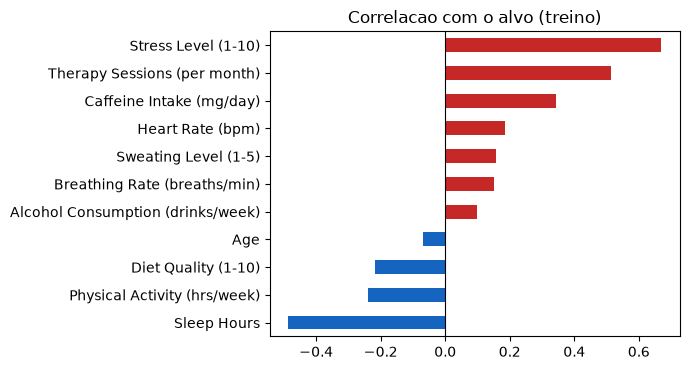

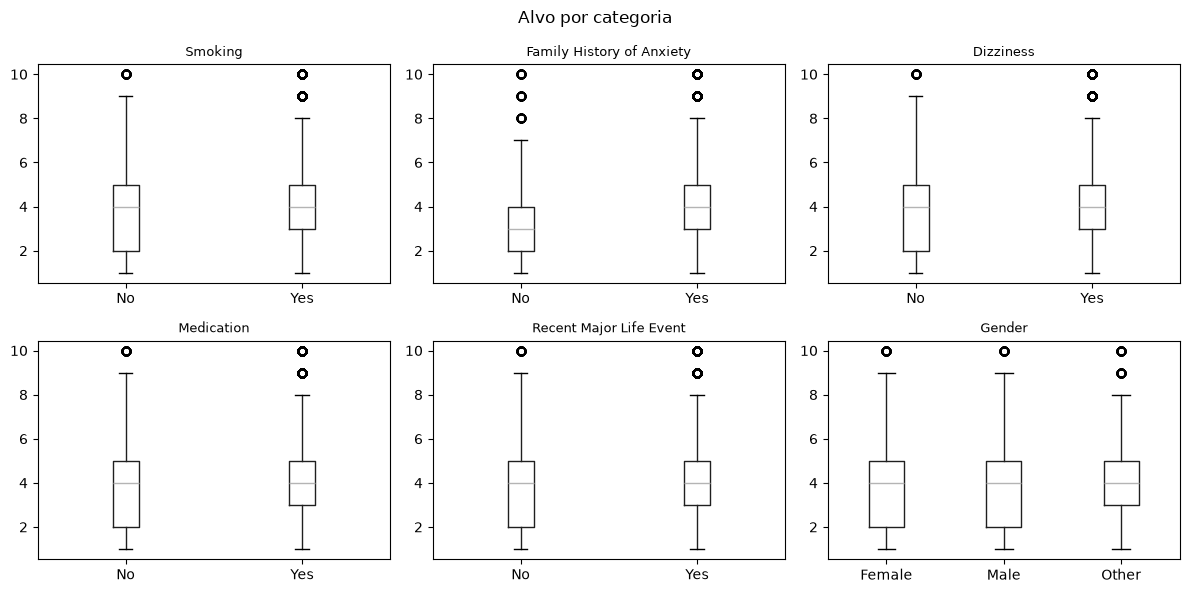

Occupation
Musician      3.73
Other         3.74
Teacher       3.79
Nurse         3.84
Athlete       3.85
Artist        3.86
Chef          3.87
Student       3.88
Scientist     3.99
Freelancer    4.00
Engineer      4.06
Lawyer        4.19
Doctor        4.26


In [8]:
corr = X_tr[COLS_NUMERICAS].corrwith(y_tr).sort_values(key=abs, ascending=False)
print(corr.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.8))
corr.sort_values().plot(kind="barh", ax=ax,
    color=["#1565C0" if v < 0 else "#C62828" for v in corr.sort_values()])
ax.axvline(0, color="black", lw=0.8); ax.set_title("Correlacao com o alvo (treino)")
plt.tight_layout(); plt.show()

cats = COLS_BINARIAS + ["Gender"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axes.ravel(), cats):
    dados.boxplot(column=ALVO, by=c, ax=ax, grid=False)
    ax.set_title(c, fontsize=9); ax.set_xlabel("")
plt.suptitle("Alvo por categoria"); plt.tight_layout(); plt.show()

print(dados.groupby("Occupation")[ALVO].mean().sort_values().round(2).to_string())

**Observação:** as mais ligadas ao alvo são estresse (r = 0,67), sessões de terapia (0,52), sono (−0,49), cafeína (0,35) e atividade física (−0,24); dieta (−0,22) vem depois, e álcool (0,10) e idade (−0,07) são as mais fracas. `Occupation` separa pouco o alvo: a média vai de 3,73 (Musician) a 4,26 (Doctor). Terapia e `Medication` aparecem ligadas a ansiedade **mais alta**: causalidade reversa, porque quem já é ansioso procura terapia e remédio.

**Decisão:** manter todas as 18 colunas. Nenhuma coluna só existe depois do alvo, então não há vazamento no sentido estrito. Idade, álcool e `Occupation` são sinais fracos, mas ficam (custo baixo; a E3 testa se fazem falta). `Therapy Sessions` e `Medication` ficam **sinalizadas**: na E3 repetir o experimento sem elas (E1: MAE 0,818 → 0,828) e decidir; nunca interpretá-las como fatores de risco.

### Pergunta 5 — Há colunas redundantes?

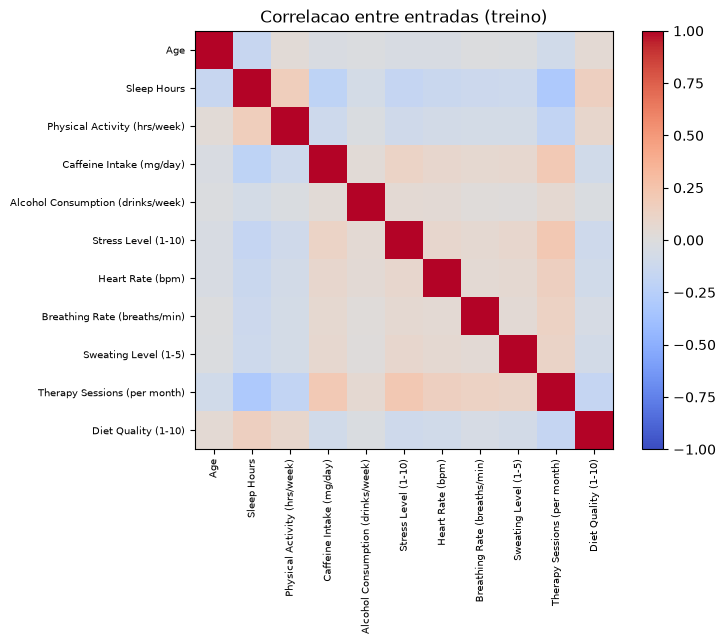

Pares com |r| > 0,9: nenhum


In [9]:
cm = X_tr[COLS_NUMERICAS].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_yticks(range(len(cm)))
ax.set_xticklabels(cm.columns, rotation=90, fontsize=7); ax.set_yticklabels(cm.columns, fontsize=7)
plt.colorbar(im); ax.set_title("Correlacao entre entradas (treino)")
plt.tight_layout(); plt.show()

pares = [(a, b, cm.loc[a, b]) for i, a in enumerate(cm.columns) for b in cm.columns[i+1:]
         if abs(cm.loc[a, b]) > 0.9]
print("Pares com |r| > 0,9:", pares if pares else "nenhum")

**Observação:** nenhum par de entradas passa de |r| > 0,9; as entradas são pouco correlacionadas entre si.

**Decisão:** nenhuma coluna removida por redundância.

---
## 5. Pré-processador

Um caminho por tipo de coluna. Ainda sem `fit`: ele só é treinado **dentro** do `Pipeline`, no `X_tr`.

In [10]:
num_cols = COLS_NUMERICAS
nom_cols = COLS_NOMINAIS
bin_cols = COLS_BINARIAS

# garante que toda coluna de X tem um caminho (remainder='drop' esconderia esquecimento)
assert set(num_cols + nom_cols + bin_cols) == set(X_tr.columns), \
    set(X_tr.columns) ^ set(num_cols + nom_cols + bin_cols)

num = Pipeline([("imp", SimpleImputer(strategy="median")),
                ("esc", StandardScaler())])
nom = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                ("ohe", OneHotEncoder(handle_unknown="ignore"))])
bina = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                 ("ohe", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))])

pre = ColumnTransformer([("num", num, num_cols),
                         ("nom", nom, nom_cols),
                         ("bin", bina, bin_cols)], remainder="drop")
pre

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

---
## 6. Teste de sanidade

Quatro checagens: sem NaN depois do transform, mesmas linhas, roda em cross-validation sem erro de categoria, e fica **acima do baseline**. Tudo no treino (`cv=5`); o teste continua trancado.

Os baselines da E1 foram medidos no teste; aqui comparo na **mesma régua** (CV no treino), refazendo B0 e B2.

In [11]:
Xt = pre.fit_transform(X_tr)
print("Shape:", Xt.shape, "| linhas iguais ao treino:", Xt.shape[0] == len(X_tr))
print("NaN depois do transform:", int(np.isnan(Xt).sum()))
print(pre.get_feature_names_out()[:10])

Shape: (8800, 32) | linhas iguais ao treino: True
NaN depois do transform: 0
['num__Age' 'num__Sleep Hours' 'num__Physical Activity (hrs/week)'
 'num__Caffeine Intake (mg/day)' 'num__Alcohol Consumption (drinks/week)'
 'num__Stress Level (1-10)' 'num__Heart Rate (bpm)'
 'num__Breathing Rate (breaths/min)' 'num__Sweating Level (1-5)'
 'num__Therapy Sessions (per month)']


In [12]:
scoring = {"MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error",
           "R2": "r2"}

# B0: media | B2: linear so com estresse | modelo simples: linear completa
b2_pre = ColumnTransformer([("s", "passthrough", ["Stress Level (1-10)"])], remainder="drop")
modelos = {
    "B0 - media do treino":        DummyRegressor(strategy="mean"),
    "B2 - linear so com estresse": Pipeline([("pre", b2_pre), ("m", LinearRegression())]),
    "Pipeline - regressao linear": Pipeline([("pre", pre), ("modelo", LinearRegression())]),
}
linhas = {}
for nome, m in modelos.items():
    r = cross_validate(m, X_tr, y_tr, cv=5, scoring=scoring)
    linhas[nome] = {"MAE": -r["test_MAE"].mean(), "MAE (desvio)": r["test_MAE"].std(),
                    "RMSE": -r["test_RMSE"].mean(), "R2": r["test_R2"].mean()}
cv_tab = pd.DataFrame(linhas).T.round(3)
display(cv_tab)

mae_pipe = cv_tab.loc["Pipeline - regressao linear", "MAE"]
mae_b2 = cv_tab.loc["B2 - linear so com estresse", "MAE"]
print(f"\n>>> Pipeline MAE {mae_pipe:.3f} contra o melhor baseline (B2) {mae_b2:.3f}: "
      f"ganho de {mae_b2 - mae_pipe:.3f} ponto.")
assert mae_pipe < mae_b2, "pipeline nao bate o baseline"

,MAE,MAE (desvio),RMSE,R2
B0 - media do treino,1.569,0.026,2.115,-0.000
B2 - linear so com estresse,1.178,0.033,1.570,0.448
Pipeline - regressao linear,0.901,0.018,1.126,0.716



>>> Pipeline MAE 0.901 contra o melhor baseline (B2) 1.178: ganho de 0.277 ponto.


### Robustez: uma linha de API

O que a E4 vai mandar: uma linha só, campo vazio, categoria nunca vista. O pipeline precisa responder sem quebrar (é o que `get_dummies` não faz).

In [13]:
pipe = Pipeline([("pre", pre), ("modelo", LinearRegression())]).fit(X_tr, y_tr)

linha = X_tr.iloc[[0]].copy()
linha["Occupation"] = "Astronauta"      # categoria nunca vista
linha["Sleep Hours"] = np.nan           # campo vazio
linha["Smoking"] = np.nan               # binaria vazia
print("Previsao com campos vazios e categoria nova:",
      round(float(pipe.predict(limpar(linha))[0]), 2))

# entrada suja passando pela limpar()
suja = X_tr.iloc[[0]].copy()
suja["Age"] = 230; suja["Smoking"] = " yes "; suja["Gender"] = " female"
print(limpar(suja)[["Age", "Smoking", "Gender"]].to_string())
print("Previsao:", round(float(pipe.predict(limpar(suja))[0]), 2))

Previsao com campos vazios e categoria nova: 3.25
       Age Smoking  Gender
10735  NaN     Yes  Female
Previsao: 3.37


---
## 7. Tabela de decisões

In [14]:
tabela = pd.DataFrame([
 ["Age", "numérica", "r = −0,07 (fraca); skew 0,10", "limite de domínio (>120 vira NaN); mediana + StandardScaler", "limpar + pipeline"],
 ["Gender", "nominal (3)", "3 categorias equilibradas (2964/2934/2902)", "padronizar texto; moda + one-hot, ignore", "limpar + pipeline"],
 ["Occupation", "nominal (13)", "13 profissões (644 a 721 linhas); média do alvo 3,73 a 4,26", "padronizar texto; moda + one-hot, ignore", "limpar + pipeline"],
 ["Sleep Hours", "numérica", "r = −0,49; skew −0,24", "limite de domínio; mediana + StandardScaler", "limpar + pipeline"],
 ["Physical Activity (hrs/week)", "numérica", "r = −0,24; skew 0,50", "limite de domínio; mediana + StandardScaler", "limpar + pipeline"],
 ["Caffeine Intake (mg/day)", "numérica", "escala em centenas; r = 0,35; skew 0,32", "limite de domínio; mediana + StandardScaler", "limpar + pipeline"],
 ["Alcohol Consumption (drinks/week)", "numérica", "0 é valor válido; r = 0,10; skew −0,03", "limite de domínio; mediana + StandardScaler", "limpar + pipeline"],
 ["Smoking", "binária", "Yes/No, ~53%/47%", "padronizar para Yes/No; moda + one-hot (drop if_binary)", "limpar + pipeline"],
 ["Family History of Anxiety", "binária", "Yes/No, ~53%/47%", "padronizar para Yes/No; moda + one-hot (drop if_binary)", "limpar + pipeline"],
 ["Stress Level (1-10)", "numérica", "maior correlação com o alvo (r = 0,67)", "limite 1-10; mediana + StandardScaler", "limpar + pipeline"],
 ["Heart Rate (bpm)", "numérica", "r = 0,19; skew −0,13", "limite 30-220; mediana + StandardScaler", "limpar + pipeline"],
 ["Breathing Rate (breaths/min)", "numérica", "r = 0,15; skew −0,15", "limite 4-60; mediana + StandardScaler", "limpar + pipeline"],
 ["Sweating Level (1-5)", "numérica (escala)", "r = 0,16; escala 1-5", "limite 1-5; mediana + StandardScaler", "limpar + pipeline"],
 ["Dizziness", "binária", "Yes/No, ~52%/48%", "padronizar para Yes/No; moda + one-hot (drop if_binary)", "limpar + pipeline"],
 ["Medication", "binária", "~52% Yes; causalidade reversa (consequência da ansiedade)", "mantida e sinalizada; ablação na E3", "limpar + pipeline"],
 ["Therapy Sessions (per month)", "numérica", "r = 0,52; skew 1,05; causalidade reversa", "mantida e sinalizada; ablação na E3; testar log1p na E3", "limpar + pipeline"],
 ["Recent Major Life Event", "binária", "Yes/No, ~51%/49%", "padronizar para Yes/No; moda + one-hot (drop if_binary)", "limpar + pipeline"],
 ["Diet Quality (1-10)", "numérica", "r = −0,22; escala 1-10", "limite 1-10; mediana + StandardScaler", "limpar + pipeline"],
 ["Anxiety Level (1-10)", "alvo", "contínuo; notas 8-10 raras", "não é transformado; sem stratify; atenção a notas altas na E3", "—"],
], columns=["Coluna", "Tipo", "Achado na EDA", "Decisão", "Onde"])
tabela

,Coluna,Tipo,Achado na EDA,Decisão,Onde
0,Age,numérica,"r = −0,07 (fraca); skew 0,10",limite de domínio (>120 vira NaN); mediana + S...,limpar + pipeline
1,Gender,nominal (3),3 categorias equilibradas (2964/2934/2902),"padronizar texto; moda + one-hot, ignore",limpar + pipeline
2,Occupation,nominal (13),13 profissões (644 a 721 linhas); média do alv...,"padronizar texto; moda + one-hot, ignore",limpar + pipeline
3,Sleep Hours,numérica,"r = −0,49; skew −0,24",limite de domínio; mediana + StandardScaler,limpar + pipeline
4,Physical Activity (hrs/week),numérica,"r = −0,24; skew 0,50",limite de domínio; mediana + StandardScaler,limpar + pipeline
5,Caffeine Intake (mg/day),numérica,"escala em centenas; r = 0,35; skew 0,32",limite de domínio; mediana + StandardScaler,limpar + pipeline
6,Alcohol Consumption (drinks/week),numérica,"0 é valor válido; r = 0,10; skew −0,03",limite de domínio; mediana + StandardScaler,limpar + pipeline
7,Smoking,binária,"Yes/No, ~53%/47%",padronizar para Yes/No; moda + one-hot (drop i...,limpar + pipeline
8,Family History of Anxiety,binária,"Yes/No, ~53%/47%",padronizar para Yes/No; moda + one-hot (drop i...,limpar + pipeline
9,Stress Level (1-10),numérica,"maior correlação com o alvo (r = 0,67)",limite 1-10; mediana + StandardScaler,limpar + pipeline


In [15]:
try:
    print(tabela.to_markdown(index=False))   # copie e cole no README
except ImportError:
    print(tabela.to_csv(index=False))

| Coluna                            | Tipo              | Achado na EDA                                               | Decisão                                                       | Onde              |
|:----------------------------------|:------------------|:------------------------------------------------------------|:--------------------------------------------------------------|:------------------|
| Age                               | numérica          | r = −0,07 (fraca); skew 0,10                                | limite de domínio (>120 vira NaN); mediana + StandardScaler   | limpar + pipeline |
| Gender                            | nominal (3)       | 3 categorias equilibradas (2964/2934/2902)                  | padronizar texto; moda + one-hot, ignore                      | limpar + pipeline |
| Occupation                        | nominal (13)      | 13 profissões (644 a 721 linhas); média do alvo 3,73 a 4,26 | padronizar texto; moda + one-hot, ignore                      | 

---
## Resumo da Entrega 2

- `limpar(df)`: só linha a linha, aplicada antes do split, reaproveitável pela API.
- Split igual ao da E1; teste trancado e não usado em nenhuma decisão.
- Pré-processador `ColumnTransformer` com 3 caminhos (numérico, nominal, binário), `handle_unknown="ignore"` e imputer em todos.
- Teste de sanidade: sem NaN, roda em cross-val, e bate o melhor baseline (B2) na mesma régua.
- Para a E3: o mesmo `pre`, trocando só o último passo do `Pipeline`.